Customer Churn Prediction
An end-to-end, leakage-aware classification workflow using the IBM Telco Customer Churn dataset. The notebook keeps the test set untouched during fitting and oversamples only the training partition. The default decision threshold is 0.50; in a retention use case, tune it to business costs using validation data.

1. Setup & Imports
Install missing packages in your environment before running (for example: pip install pandas numpy scikit-learn imbalanced-learn xgboost matplotlib seaborn shap).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [3]:
%pip install -U ipywidgets

   ---------------------------------------- 0.0/2.2 MB ? eta -:--:--
   ------------------ --------------------- 1.0/2.2 MB 7.7 MB/s eta 0:00:01
   ---------------------------------------- 2.2/2.2 MB 7.6 MB/s  0:00:00

   ------------- -------------------------- 1/3 [jupyterlab_widgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   -------------------------- ------------- 2/3 [ipywidgets]
   ---------------------------------------- 3/3 [ipywidgets]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve,
                             roc_auc_score, precision_score, recall_score, f1_score)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import shap

RANDOM_STATE = 42
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid', context='notebook')

2. Data Loading & Exploratory Data Analysis (EDA)
The public IBM sample is loaded from GitHub. If the download is unavailable, replace DATA_URL with a local copy of WA_Fn-UseC_-Telco-Customer-Churn.csv.

In [6]:
DATA_URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(DATA_URL)
print(f"Shape: {df.shape}")
display(df.head())
df.info()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Missing values by column (top):


,missing
TotalCharges,11
gender,0
SeniorCitizen,0
Partner,0
customerID,0
Dependents,0
tenure,0
MultipleLines,0
PhoneService,0
OnlineSecurity,0


Churn counts:


,count
Churn,
No,5174
Yes,1869


Churn fraction:


,fraction
Churn,
No,0.73463
Yes,0.26537


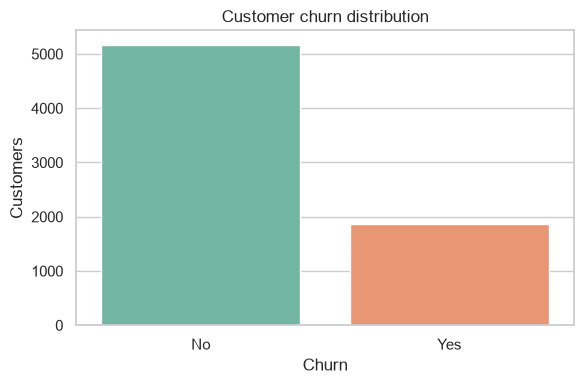

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
# TotalCharges is stored as text with blank strings for some new customers.
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].replace(r'^\s*$', np.nan, regex=True), errors='coerce')
print('Missing values by column (top):')
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame('missing'))

# Drop identifier and rows with missing target; median-impute the few missing TotalCharges
# values after the split using the training median (see preprocessing section).
print('Churn counts:')
display(df['Churn'].value_counts(dropna=False).to_frame('count'))
print('Churn fraction:')
display(df['Churn'].value_counts(normalize=True).to_frame('fraction'))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x='Churn', hue='Churn', legend=False, palette='Set2', ax=ax)
ax.set_title('Customer churn distribution')
ax.set_ylabel('Customers')
plt.tight_layout()
plt.show()
display(df.describe(include='all').T.head(20))

3. Data Preprocessing & Pipeline Protection
First split raw features and labels (80/20, stratified, seed 42). Then learn missing-value medians and scaling parameters from training data only. One-hot encoding is applied to each partition and test columns are aligned to training columns. SMOTE is applied only to the processed training data; the test set retains the original class distribution.

In [8]:
# Target encode; customerID is an identifier and is excluded from predictors.
model_df = df.dropna(subset=['Churn']).copy()
y = model_df['Churn'].map({'No': 0, 'Yes': 1}).astype(int)
X_raw = model_df.drop(columns=['Churn', 'customerID'], errors='ignore')

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print('Split sizes:', X_train_raw.shape, X_test_raw.shape)
print('Churn rates train/test:', round(y_train.mean(), 3), round(y_test.mean(), 3))

Split sizes: (5634, 19) (1409, 19)
Churn rates train/test: 0.265 0.265


In [10]:
# Median imputation for numeric values is learned on training data, then applied to test.
continuous_features = ['tenure', 'MonthlyCharges', 'TotalCharges']
train_medians = X_train_raw[continuous_features].median()
X_train_raw.loc[:, continuous_features] = X_train_raw[continuous_features].fillna(train_medians)
X_test_raw.loc[:, continuous_features] = X_test_raw[continuous_features].fillna(train_medians)

# One-hot encode categoricals. Align test columns to the training feature schema.
X_train = X_train.astype(float)
X_test = X_test.astype(float)

scaler = StandardScaler()
X_train.loc[:, continuous_features] = scaler.fit_transform(X_train[continuous_features])
X_test.loc[:, continuous_features] = scaler.transform(X_test[continuous_features])

# Keep DataFrames and column names for interpretation; ensure numeric values throughout.
X_train = X_train.astype(float)
X_test = X_test.astype(float)
print('Encoded dimensions:', X_train.shape, X_test.shape)
print('Missing after preprocessing:', int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()))

# Resample training data only. Test data is never passed to SMOTE.
smote = SMOTE(random_state=RANDOM_STATE)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)
print('Training class counts before:', y_train.value_counts().to_dict())
print('Training class counts after SMOTE:', pd.Series(y_train_sm).value_counts().to_dict())

Encoded dimensions: (5634, 45) (1409, 45)
Missing after preprocessing: 0 0
Training class counts before: {0: 4139, 1: 1495}
Training class counts after SMOTE: {0: 4139, 1: 4139}


4. Model Training
A compact grid search tunes logistic regression using stratified 3-fold CV and ROC-AUC on the resampled training set. Random Forest and XGBoost provide nonlinear comparisons. The test set is reserved for the final evaluation.

In [11]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

logit_search = GridSearchCV(
    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    param_grid={'C': [0.1, 1.0, 10.0], 'class_weight': [None, 'balanced']},
    scoring='roc_auc', cv=cv, n_jobs=-1, refit=True
)
logit_search.fit(X_train_sm, y_train_sm)
logit_model = logit_search.best_estimator_
print('Best logistic regression parameters:', logit_search.best_params_)
print(f'Best CV ROC-AUC: {logit_search.best_score_:.3f}')

rf_model = RandomForestClassifier(
    n_estimators=400, max_depth=None, min_samples_leaf=2,
    random_state=RANDOM_STATE, n_jobs=-1
)
rf_model.fit(X_train_sm, y_train_sm)

xgb_model = XGBClassifier(
    n_estimators=400, max_depth=4, learning_rate=0.05,
    subsample=0.9, colsample_bytree=0.9,
    objective='binary:logistic', eval_metric='logloss',
    random_state=RANDOM_STATE, n_jobs=-1
)
xgb_model.fit(X_train_sm, y_train_sm)

models = {'Logistic Regression': logit_model, 'Random Forest': rf_model, 'XGBoost': xgb_model}

Best logistic regression parameters: {'C': 1.0, 'class_weight': None}
Best CV ROC-AUC: 0.854


5. Model Evaluation & Interpretation
Reports show per-class precision, recall, and F1. For churn class 1, recall measures the fraction of actual churners identified; high recall may be useful when missing a churner is costly, although it can increase false positives.

In [12]:
results = {}
for name, model in models.items():
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    results[name] = {'pred': pred, 'proba': proba, 'auc': roc_auc_score(y_test, proba)}
    print(f'\n{name} | ROC-AUC={results[name]["auc"]:.3f}')
    print(classification_report(y_test, pred, target_names=['No churn (0)', 'Churn (1)'], digits=3))
    print(f'Churn recall: {recall_score(y_test, pred, pos_label=1):.3f}')
    print('Confusion matrix [true rows, predicted columns]:\n', confusion_matrix(y_test, pred))

summary = pd.DataFrame([
    {'model': name, 'ROC-AUC': score['auc'],
     'churn_precision': precision_score(y_test, score['pred'], pos_label=1),
     'churn_recall': recall_score(y_test, score['pred'], pos_label=1),
     'churn_f1': f1_score(y_test, score['pred'], pos_label=1)}
    for name, score in results.items()
]).sort_values('ROC-AUC', ascending=False)
display(summary)


Logistic Regression | ROC-AUC=0.841
              precision    recall  f1-score   support

No churn (0)      0.905     0.719     0.801      1035
   Churn (1)      0.504     0.791     0.616       374

    accuracy                          0.738      1409
   macro avg      0.705     0.755     0.709      1409
weighted avg      0.799     0.738     0.752      1409

Churn recall: 0.791
Confusion matrix [true rows, predicted columns]:
 [[744 291]
 [ 78 296]]

Random Forest | ROC-AUC=0.830
              precision    recall  f1-score   support

No churn (0)      0.861     0.829     0.844      1035
   Churn (1)      0.570     0.628     0.598       374

    accuracy                          0.776      1409
   macro avg      0.715     0.729     0.721      1409
weighted avg      0.784     0.776     0.779      1409

Churn recall: 0.628
Confusion matrix [true rows, predicted columns]:
 [[858 177]
 [139 235]]

XGBoost | ROC-AUC=0.836
              precision    recall  f1-score   support

No churn (0)

,model,ROC-AUC,churn_precision,churn_recall,churn_f1
0,Logistic Regression,0.840680,0.504259,0.791444,0.616025
2,XGBoost,0.836327,0.585242,0.614973,0.599739
1,Random Forest,0.829804,0.570388,0.628342,0.597964


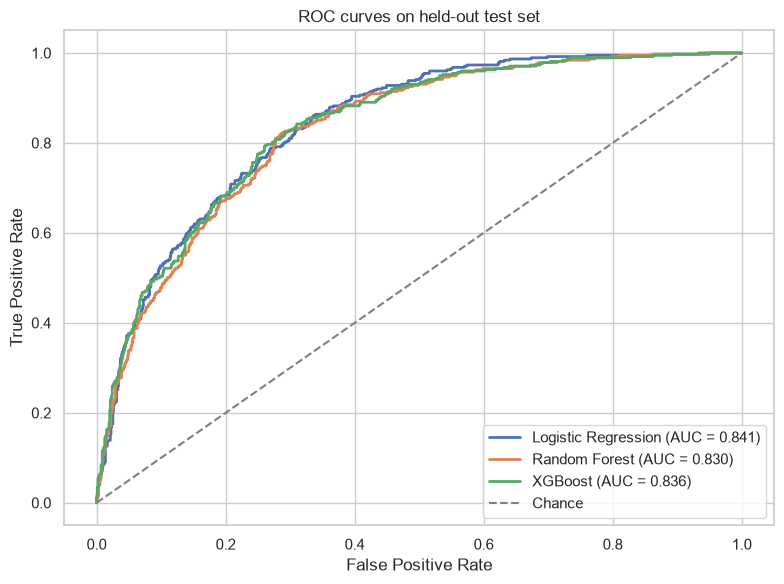

In [13]:
fig, ax = plt.subplots(figsize=(8, 6))
for name, score in results.items():
    fpr, tpr, _ = roc_curve(y_test, score['proba'])
    ax.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {score["auc"]:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='ROC curves on held-out test set')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

Feature drivers
The tuned logistic regression provides transparent signed coefficients; XGBoost provides model-based feature importance. SHAP TreeExplainer is included for local/global explanations. For a full production interpretation workflow, consider explaining a model trained on the original (non-SMOTE) distribution and validating explanations with domain experts.

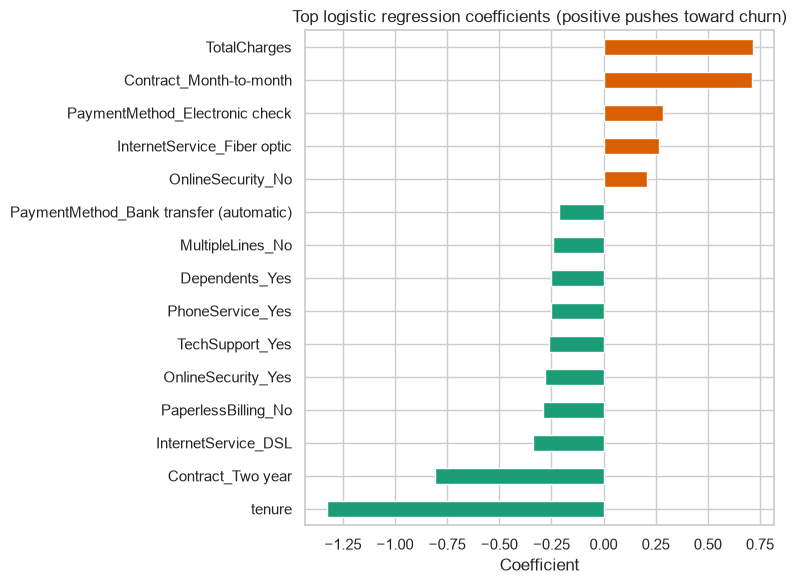

,xgboost_importance
Contract_Month-to-month,0.325406
InternetService_Fiber optic,0.079936
OnlineSecurity_No,0.071794
TechSupport_No,0.039053
PaymentMethod_Electronic check,0.036437
Contract_Two year,0.033342
Dependents_Yes,0.023976
OnlineBackup_No,0.022819
StreamingMovies_Yes,0.022603
SeniorCitizen,0.022600


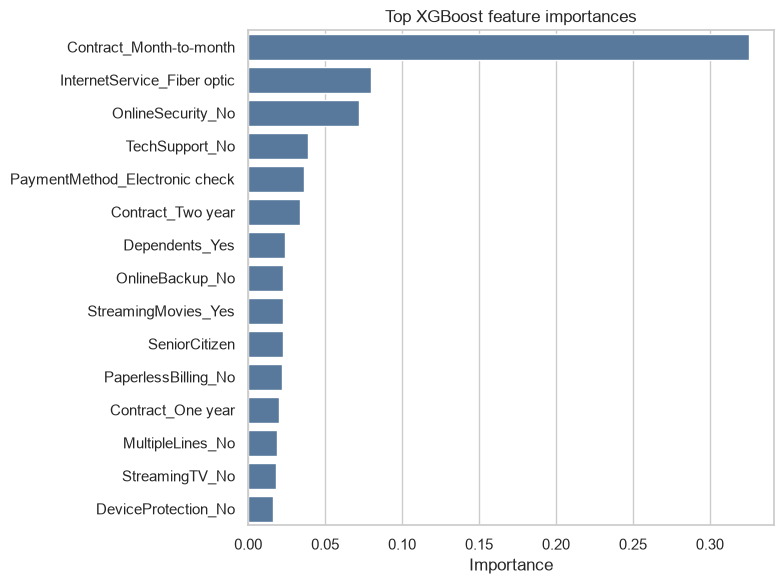

In [14]:
# Logistic regression coefficient magnitude gives a quick linear-model ranking.
coef = pd.Series(logit_model.coef_[0], index=X_train.columns)
coef_rank = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15)
fig, ax = plt.subplots(figsize=(8, 6))
coef_rank.sort_values().plot(kind='barh', ax=ax, color=np.where(coef_rank.sort_values() > 0, '#d95f02', '#1b9e77'))
ax.set_title('Top logistic regression coefficients (positive pushes toward churn)')
ax.set_xlabel('Coefficient')
plt.tight_layout()
plt.show()

# XGBoost gain-based importance (model-specific ranking).
xgb_importance = pd.Series(xgb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)
display(xgb_importance.to_frame('xgboost_importance'))
plt.figure(figsize=(8, 6))
sns.barplot(x=xgb_importance.values, y=xgb_importance.index, color='#4c78a8')
plt.title('Top XGBoost feature importances')
plt.xlabel('Importance')
plt.ylabel('')
plt.tight_layout()
plt.show()

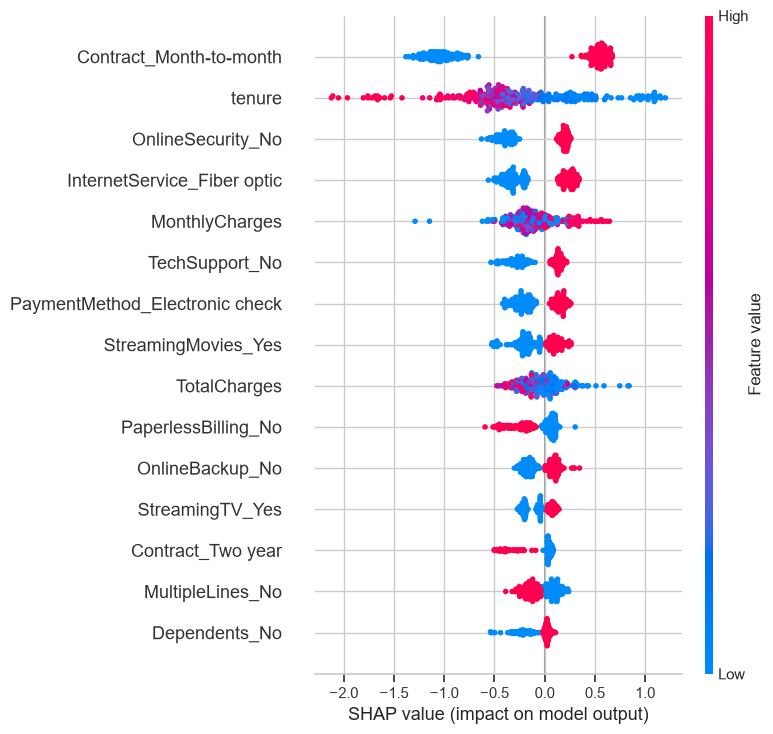

In [15]:
# SHAP values on a small held-out sample to keep runtime manageable.
# TreeExplainer supports the fitted XGBoost tree ensemble.
try:
    explain_sample = X_test.sample(n=min(300, len(X_test)), random_state=RANDOM_STATE)
    explainer = shap.TreeExplainer(xgb_model)
    shap_values = explainer.shap_values(explain_sample)
    shap.summary_plot(shap_values, explain_sample, max_display=15, show=True)
except Exception as exc:
    print(f'SHAP explanation could not be generated in this environment: {exc}')